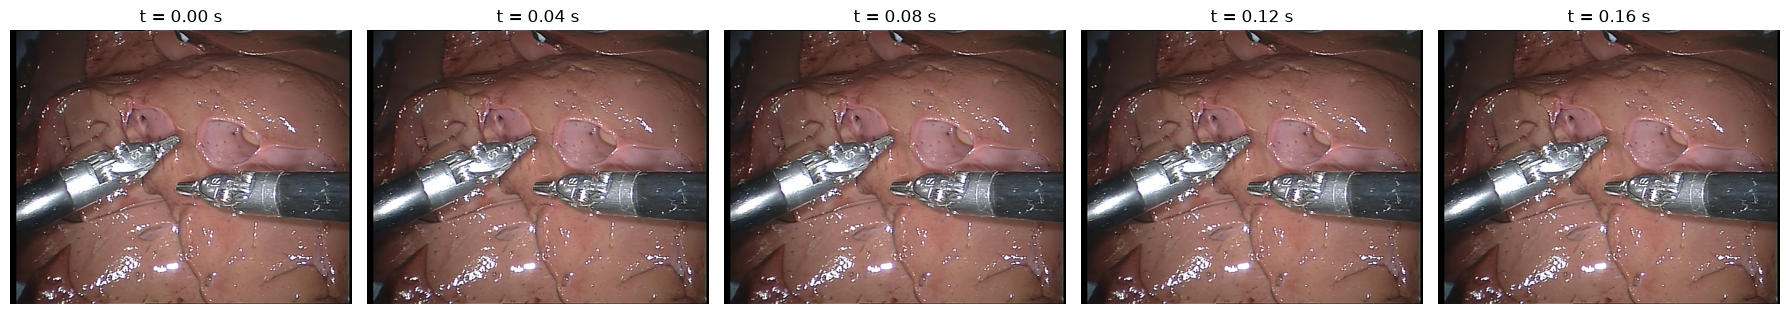

Total extracted frames: 1107
First image: /home/ahmed-cheruvattam/Instrument Tracking/EndoVisPoseAnnotation/Tracking_Robotic_Training/Training/Dataset1/EndoVis_Frames_set1/Dataset1/img_000001_raw.png


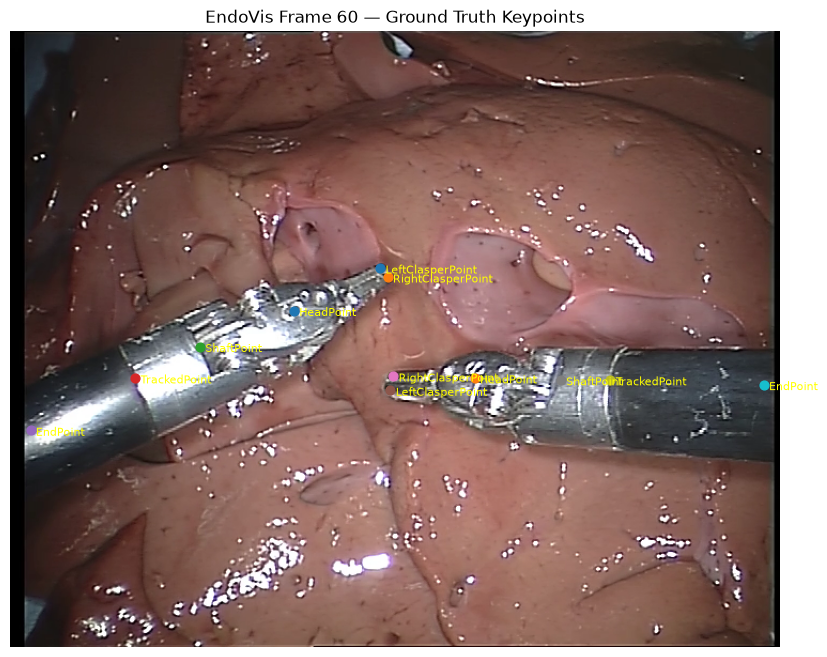

Annotated frames: 210
Training frames: 168
Validation frames: 42
Duplicate clasper point: img_000130_raw.png tool1
train: 167/168 frames converted
val: 42/42 frames converted


In [1]:
# import json
# import os
# from glob import glob

# # Locate repository in Ubuntu home directory
# path = os.path.expanduser("~/Instrument Tracking/EndoVisPoseAnnotation/train_labels/train1_labels.json")

# # Load JSON annotations
# with open(path, "r") as f:
#     labels = json.load(f)

# print(type(labels))
# print(str(labels)[:2000])

import cv2
import pandas as pd
import os
from glob import glob
import matplotlib.pyplot as plt
import json

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

project_dir = os.path.expanduser("~/Instrument Tracking")
output_dir = os.path.join(
    project_dir, "EndoVisPoseAnnotation",
    "Tracking_Robotic_Training", "Training", "Dataset1",
    "EndoVis_Frames_set1", "Dataset1"
)
df = pd.read_csv(os.path.join(output_dir, "timestamps.csv"))
for i in range(min(5, len(df))):

    filename = df.iloc[i]["filename"]
    timestamp = df.iloc[i]["timestamp_seconds"]

    image = cv2.imread(str(os.path.join(output_dir, filename)))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    axes[i].imshow(image)

    axes[i].set_title(f"t = {timestamp:.2f} s")

    axes[i].axis("off")

plt.tight_layout()
plt.show()

images = sorted(glob(os.path.join(output_dir, "*.png")))

print("Total extracted frames:", len(images))
print("First image:", images[0] if images else "No images found")

# Load annotations
label_path = os.path.join(project_dir, "EndoVisPoseAnnotation", "train_labels", "train1_labels.json")

with open(label_path, "r") as f:
    labels = json.load(f)

# Select frame 60
frame_number = 60

record = labels[frame_number - 1]

image_path = os.path.join(output_dir, f"img_{frame_number:06d}_raw.png")

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(image)

# Overlay keypoints
for annotation in record["annotations"]:

    x = annotation["x"]
    y = annotation["y"]

    plt.scatter(x, y, s=40)

    plt.text(
        x + 5,
        y + 5,
        annotation["class"],
        fontsize=8,
        color="yellow"
    )

plt.title("EndoVis Frame 60 — Ground Truth Keypoints")
plt.axis("off")
plt.show()


# Original annotation file
label_path = os.path.join(project_dir, "EndoVisPoseAnnotation", "train_labels", "train1_labels.json")

# New YOLO dataset
yolo_dir = os.path.join(project_dir, "EndoVis_YOLO_Pose")

for split in ["train", "val"]:
    os.makedirs(os.path.join(yolo_dir, "images", split), exist_ok=True)
    os.makedirs(os.path.join(yolo_dir, "labels", split), exist_ok=True)

with open(label_path, "r") as f:
    labels = json.load(f)

# Fixed order of surgical instrument landmarks
keypoint_names = [
    "LeftClasperPoint",
    "RightClasperPoint"
]

# Only frames with annotations
annotated_records = [
    record for record in labels
    if len(record["annotations"]) > 0
]

print("Annotated frames:", len(annotated_records))

# Sequential train/validation split
split_idx = int(0.8 * len(annotated_records))

train_records = annotated_records[:split_idx]
val_records = annotated_records[split_idx:]

print("Training frames:", len(train_records))
print("Validation frames:", len(val_records))

import numpy as np
import shutil

def convert_to_yolo(record, split):

    filename = os.path.basename(record["filename"])
    image_path = os.path.join(output_dir, filename)

    image = cv2.imread(str(image_path))

    if image is None:
        print("Missing image:", filename)
        return False

    height, width = image.shape[:2]

    # Group keypoints by surgical instrument
    tools = {}


    for annotation in record["annotations"]:

        tool_id = annotation["id"]
        keypoint_type = annotation["class"]

        # Ignore landmarks other than the two clasper points
        if keypoint_type not in keypoint_names:
            continue

        if tool_id not in tools:
            tools[tool_id] = {}

        # Flag conflicting duplicate annotations
        if keypoint_type in tools[tool_id]:
            print("Duplicate clasper point:", filename, tool_id)
            return False

        tools[tool_id][keypoint_type] = (
            annotation["x"],
            annotation["y"]
        )
    yolo_lines = []

    for tool_id, points in tools.items():

        # Require all six keypoints
        if not all(name in points for name in keypoint_names):
            print("Missing clasper point:", filename, tool_id)
            return False


        coords = np.array([
          points["LeftClasperPoint"],
          points["RightClasperPoint"]
              ])

        # Generate approximate bounding box
        padding = 20

        xmin = max(0, coords[:, 0].min() - padding)
        xmax = min(width, coords[:, 0].max() + padding)

        ymin = max(0, coords[:, 1].min() - padding)
        ymax = min(height, coords[:, 1].max() + padding)

        # Normalize bounding box
        xc = (xmin + xmax) / (2 * width)
        yc = (ymin + ymax) / (2 * height)

        w = (xmax - xmin) / width
        h = (ymax - ymin) / height

        # Class 0 = surgical instrument
        values = [0, xc, yc, w, h]

        # Append keypoints
        for x, y in coords:

            values.extend([
                x / width,
                y / height,
                2
            ])

        yolo_lines.append(
            " ".join(map(str, values))
        )

    # Save image
    destination_image = os.path.join(yolo_dir, "images", split, filename)

    shutil.copy2(image_path, destination_image)

    # Save YOLO annotation
    destination_label = os.path.join(
        yolo_dir, "labels", split,
        f"{os.path.splitext(filename)[0]}.txt"
    )

    with open(destination_label, "w") as f:
        f.write("\n".join(yolo_lines) + "\n")

    return True


# Convert training and validation data
for split, records in [
    ("train", train_records),
    ("val", val_records)
]:

    converted = 0

    for record in records:

        if convert_to_yolo(record, split):
            converted += 1

    print(f"{split}: {converted}/{len(records)} frames converted")

    label_files = sorted(glob(os.path.join(yolo_dir, "labels", "train", "*.txt")))

